# Hof Co-op: planet population analysis (add-planets)

Analysis of runs made with `run_model_Hof.py` and `config/popsynth/DiscConfig_Hof_add-planets.json` (planets with `Mp = "SI"` are inserted where planetesimals form, then grown and migrated with the Bitsch model).

Units: `t` in the HDF5 file is in **yr** (shown here in Myr); `Rp` in AU; `Mcs`, `Mes` in M⊕.

In [5]:
# ==== IMPORTS AND DIRECTORIES ====
# (Hof, 2026-11-11) Set-up cell for the planet-population ("add-planets") analysis.
# Runs come from run_model_Hof.py with config/popsynth/DiscConfig_Hof_add-planets.json.
import os
import re

import h5py
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

# Directory holding the add-planets pilot output (.h5). The run is written by
# run_model_Hof.py; per-planet series are HDF5 groups Mcs/<ip>, Mes/<ip>, Rp/<ip>
# with one row per entry of the dataset "t" [yr] (see run_model_Hof.py,
# create_planet_datasets() / write_planet_row()).
DATADIR_PILOT = "/home/imontesd/scratch/output/DiscEvolution/popsynth/add-planets/pilot_v1"

# Where figures are saved (None = do not save). Created on first save.
FIGDIR = None

### Planet evolution tracks (pilot v1)

Total mass (core + envelope, M⊕) against orbital radius (AU) for every planet in one pilot run. Same style as the *Planet evolution tracks* cell in `HJpaper.ipynb` (`compare_models_onepanel`):
- each line is one planet, coloured by its starting radius;
- the open circle is where the planet starts (its insertion point for `"SI"` planets);
- filled circles mark every 0.33 Myr, more opaque as time goes on.

This plot shows one model only. It uses a log colour scale from 0.2 to 30 AU (HJpaper used a linear 0–30 AU scale).

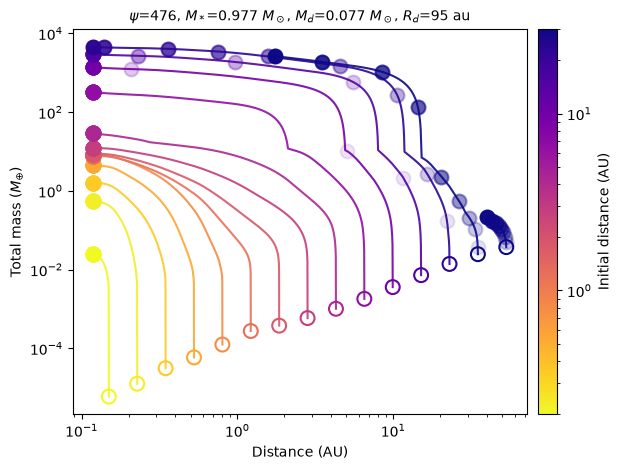

t_end = 3.000 Myr, complete = True, N planets = 15
 ip  cfg R_ins[AU] t_form[Myr] R_fin[AU]    Mc[ME]    Me[ME]  Mtot[ME]
  0    1     0.150       0.000     0.119    0.0241  0.000563    0.0247
  1    2     0.228       0.000     0.119     0.538   0.00171      0.54
  2    3     0.346       0.000     0.119      1.61     0.012      1.63
  3    4     0.526       0.000     0.119      4.35    0.0809      4.43
  4    5     0.801       0.000     0.119      7.84     0.268      8.11
  5    6     1.218       0.001     0.119      7.54     0.265      7.81
  6    7     1.853       0.001     0.119      8.45     0.356       8.8
  7    8     2.819       0.003     0.119      11.5     0.751      12.3
  8    9     4.288       0.006     0.119      8.54      20.2      28.8
  9   10     6.524       0.012     0.119      5.91       317       323
 10   11     9.924       0.025     0.119      5.39  1.39e+03  1.39e+03
 11   12    15.096       0.053     0.119      5.42  2.98e+03  2.98e+03
 12   13    22.964       0

In [6]:
# ==== PLANET EVOLUTION TRACKS (single run) ====
# (Hof, 2026-11-11) Total-mass growth tracks M_core + M_env [Mearth] vs orbital
# radius R_p [AU] for every planet in ONE run_model_Hof.py output file.
# Modelled on compare_models_onepanel() in HJpaper.ipynb ("Planet evolution tracks"
# cell, the paper's Fig. 6), with the same conventions:
#   * one line per planet, coloured by its starting radius ("Initial distance (AU)"
#     colour bar, cmap "plasma_r");
#   * circle markers every TIME_MARKER_INTERVAL_MYR [Myr], whose fill opacity grows
#     with time (alpha = t_mark / t_max), so you can read how fast each planet moved;
#   * the starting point is an OPEN circle.
# Differences from HJpaper (needed for this run):
#   1. One model per panel (HJpaper overlays two models, solid vs dashed).
#   2. Planets with Mp = "SI" are inserted only when planetesimals form at their
#      radius (streaming instability), so they may appear AFTER t = 0. run_model_Hof.py
#      backfills their rows with NaN until then (see _make_backfilled()). Here:
#        - the start point / colour comes from the Rp/<ip> attribute R_insert_au [AU]
#          (HJpaper uses Rp[ip][0], which would be NaN for a late insertion);
#        - the open circle sits at the INSERTION point (= t = 0 for planets present
#          from the start), and time markers are drawn only after insertion.
#   3. Colour scale is LOGARITHMIC between 0.2 and 30 AU (the planets.Rp range in
#      DiscConfig_Hof_add-planets.json). HJpaper used a linear 0-30 AU scale; with
#      8 of 16 radii inside 3 AU a linear scale would make those lines look alike.
#   4. A planet that the code stops writing early (e.g. removed at the inner edge)
#      has a shorter series than "t"; time is truncated to its length.
# Units: t [yr] in the file -> Myr here (/1e6); Rp [AU]; Mcs, Mes [Mearth].

PILOT_FILE = os.path.join(
    DATADIR_PILOT,
    "hof_add-planets_pilotv1_gamma1_psi476.0_erad0.967521_Ms0.977_aSS1.0e-05"
    "_Mdot7.4e-08_M7.7e-02_Rd9.5e+01.h5",
)

TIME_MARKER_INTERVAL_MYR = 0.33   # Myr between time markers (same as HJpaper)
R_COLOR_LIM_AU = (0.2, 30.0)      # AU, colour-bar range (log scale), see note 3


def load_planet_tracks_Hof(fname):
    """
    Read the per-planet time series of one run_model_Hof.py output file.

    Returns a dict:
        t_yr    : (nt,) time of each planet row [yr]  (dataset "t")
        planets : list (HDF5 index order = insertion order) of dicts with
                  ip            HDF5 index (str key of the Rp group)
                  config_index  position in config planets.Rp / planets.Mp (-1 if absent)
                  R_insert_au   insertion radius [AU]
                  t_form_Myr    insertion time [Myr]
                  Rp_au         (n,) orbital radius [AU]   (NaN before insertion)
                  Mc_Mearth     (n,) core mass [Mearth]
                  Me_Mearth     (n,) envelope mass [Mearth]
        params  : run parameters parsed from the filename (psi, erad, Ms [Msun],
                  aSS, Mdot [Msun/yr], M [Msun], Rd [AU]); missing tokens -> NaN
        complete: h5 attribute "complete" (False if the run did not finish)
    """
    out = {"planets": [], "params": {}}
    base = os.path.basename(fname)
    # Filename tokens written by run_model_Hof.py::output_filename()
    for key, pat in [("psi", r"_psi([0-9.eE+-]+?)_"), ("erad", r"_erad([0-9.eE+-]+?)_"),
                     ("Ms", r"_Ms([0-9.eE+-]+?)_"), ("aSS", r"_aSS([0-9.eE+-]+?)_Mdot"),
                     ("Mdot", r"_Mdot([0-9.eE+-]+?)_M"), ("M", r"_M([0-9.eE+-]+?)_Rd"),
                     ("Rd", r"_Rd([0-9.eE+-]+?)\.h5$")]:
        m = re.search(pat, base)
        out["params"][key] = float(m.group(1)) if m else np.nan

    with h5py.File(fname, "r") as f:
        out["t_yr"] = np.asarray(f["t"][()], dtype=float)                 # yr
        out["complete"] = bool(f.attrs.get("complete", False))
        if "Rp" not in f or len(f["Rp"].keys()) == 0:
            print(f"No planets in {base} (include_planets off, or none inserted yet).")
            return out
        for ip in sorted(f["Rp"].keys(), key=int):
            Rp = np.asarray(f["Rp"][ip][()], dtype=float)                 # AU
            Mc = np.asarray(f["Mcs"][ip][()], dtype=float)                # Mearth
            Me = np.asarray(f["Mes"][ip][()], dtype=float)                # Mearth
            a = f["Rp"][ip].attrs
            finite = np.isfinite(Rp)
            # Fallbacks for files written before the attributes existed:
            # first finite radius / time of the first finite row.
            R_ins = float(a["R_insert_au"]) if "R_insert_au" in a else (
                Rp[finite][0] if finite.any() else np.nan)
            t_ins_yr = float(a["t_form_yr"]) if "t_form_yr" in a else (
                out["t_yr"][np.argmax(finite)] if finite.any() else np.nan)
            out["planets"].append({
                "ip": ip,
                "config_index": int(a.get("config_index", -1)),
                "R_insert_au": R_ins,
                "t_form_Myr": t_ins_yr / 1e6,                              # yr -> Myr
                "Rp_au": Rp, "Mc_Mearth": Mc, "Me_Mearth": Me,
            })
    return out


def plot_planet_tracks_Hof(fname, planets=None, cmap="plasma_r",
                           time_marker_interval=TIME_MARKER_INTERVAL_MYR,
                           r_color_lim=R_COLOR_LIM_AU, xlim=None, ylim=None,
                           figdir=None):
    """
    Plot total mass (M_core + M_env) [Mearth] vs R_p [AU] for each planet of one run.
        planets : iterable of HDF5 planet indices (int) to draw; None = all
        figdir  : directory to save a PNG into (None = do not save)
    Returns (fig, ax, data) where data is the load_planet_tracks_Hof() dict.
    """
    data = load_planet_tracks_Hof(fname)
    if not data["planets"]:
        return None, None, data
    t_all_Myr = data["t_yr"] / 1e6                                         # yr -> Myr
    t_max = np.nanmax(t_all_Myr)                                           # Myr, end of run
    sel = [p for p in data["planets"] if planets is None or int(p["ip"]) in planets]

    norm = mpl.colors.LogNorm(vmin=r_color_lim[0], vmax=r_color_lim[1])   # AU
    cmap_obj = plt.get_cmap(cmap)

    fig, ax = plt.subplots()
    for p in sel:
        c = cmap_obj(norm(p["R_insert_au"]))
        n = len(p["Rp_au"])
        t_Myr = t_all_Myr[:n]                                              # note 4
        x = p["Rp_au"]                                                     # AU
        y = p["Mc_Mearth"] + p["Me_Mearth"]                                # Mearth
        ok = np.isfinite(x) & np.isfinite(y) & (y > 0)                     # drop NaN backfill
        if not ok.any():
            continue
        ax.loglog(x[ok], y[ok], color=c, linestyle="-", alpha=0.9)

        # Open circle at the insertion point (HJpaper: open circle at t = 0)
        i0 = np.argmax(ok)
        ax.scatter(x[i0], y[i0], facecolors="none", edgecolors=c, s=100,
                   marker="o", linewidths=1.5, zorder=5)

        # Filled markers every time_marker_interval [Myr] after insertion, with fill
        # opacity = t_mark / t_max (HJpaper's "progressive filling")
        for t_mark in np.arange(time_marker_interval, t_max, time_marker_interval):
            if t_mark < t_Myr[i0] or t_mark > t_Myr[ok][-1]:
                continue                       # planet not yet inserted / no longer written
            idx = np.argmin(np.abs(t_Myr - t_mark))
            if not ok[idx]:
                continue
            ax.scatter(x[idx], y[idx], color=c, edgecolors=c, s=100, marker="o",
                       alpha=t_mark / t_max, linewidths=1.5, zorder=5)

    ax.set_xlabel("Distance (AU)")
    ax.set_ylabel("Total mass ($M_⊕$)")
    if xlim: ax.set_xlim(xlim)
    if ylim: ax.set_ylim(ylim)

    # Short run label: wind strength psi (dimensionless), M* [Msun], initial disc
    # mass M [Msun] and characteristic radius Rd [AU], from the filename
    pr = data["params"]
    ax.set_title(rf"$\psi$={pr['psi']:g}, $M_*$={pr['Ms']:g} $M_\odot$, "
                 rf"$M_d$={pr['M']:.2g} $M_\odot$, $R_d$={pr['Rd']:g} au"
                 + ("" if data["complete"] else "  [run incomplete]"), fontsize=10)

    sm = mpl.cm.ScalarMappable(cmap=cmap_obj, norm=norm)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, pad=0.02)
    cbar.set_label("Initial distance (AU)")
    plt.tight_layout()

    if figdir:
        os.makedirs(figdir, exist_ok=True)
        outname = os.path.join(figdir, os.path.basename(fname).replace(".h5", "_tracks_Mtot_vs_R.png"))
        fig.savefig(outname, dpi=200)
        print(f"Saved {outname}")
    return fig, ax, data


fig, ax, tracks_pilot = plot_planet_tracks_Hof(PILOT_FILE, figdir=FIGDIR)
plt.show()

# Summary table: one line per planet (HDF5 insertion order)
print(f"t_end = {tracks_pilot['t_yr'][-1] / 1e6:.3f} Myr, complete = {tracks_pilot['complete']}, "
      f"N planets = {len(tracks_pilot['planets'])}")
print(f"{'ip':>3} {'cfg':>4} {'R_ins[AU]':>9} {'t_form[Myr]':>11} {'R_fin[AU]':>9} "
      f"{'Mc[ME]':>9} {'Me[ME]':>9} {'Mtot[ME]':>9}")
for p in tracks_pilot["planets"]:
    last = np.flatnonzero(np.isfinite(p["Rp_au"]))
    j = last[-1] if last.size else -1
    print(f"{p['ip']:>3} {p['config_index']:>4} {p['R_insert_au']:9.3f} {p['t_form_Myr']:11.3f} "
          f"{p['Rp_au'][j]:9.3f} {p['Mc_Mearth'][j]:9.3g} {p['Me_Mearth'][j]:9.3g} "
          f"{p['Mc_Mearth'][j] + p['Me_Mearth'][j]:9.3g}")

### Planet total mass vs time (pilot v1)

Total mass (core + envelope, M⊕) against time (Myr) for the same planets as the tracks plot above, with the same colour coding (starting radius, log scale 0.2–30 AU).
- An open circle marks insertion: t = 0, or the insertion time for `"SI"` planets.
- A filled circle marks the last saved point.

The time axis is linear by default; call with `logt=True` for a log axis, which shows the early growth more clearly. This cell reuses `tracks_pilot` from the cell above, so run that cell first.

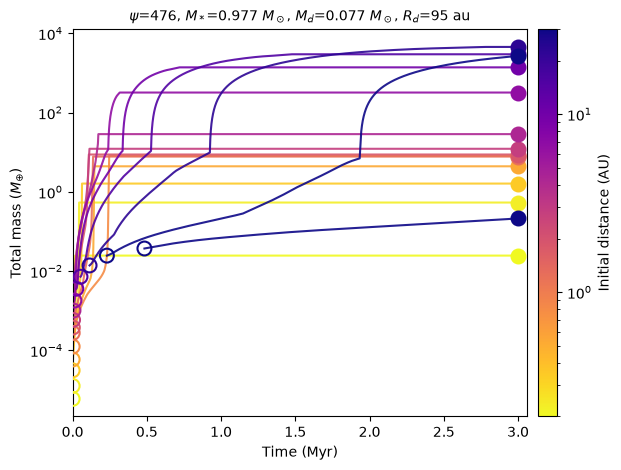

In [7]:
# ==== PLANET TOTAL MASS vs TIME (single run) ====
# (Hof, 2026-11-11) Companion to the tracks cell above: total mass
# M_core + M_env [Mearth] against time t [Myr] for every planet of the same run.
# HJpaper.ipynb has no mass-vs-time panel, so this keeps the conventions of the
# tracks cell (and of HJpaper's compare_models_onepanel) instead:
#   * one line per planet, coloured by insertion radius R_insert_au [AU], with the
#     same log colour scale (R_COLOR_LIM_AU) and "Initial distance (AU)" colour bar;
#   * OPEN circle at the insertion point (t_form; t = 0 for planets present at start);
#   * FILLED circle at the last written row (final mass, or the moment the code
#     stopped writing the planet).
# The 0.33 Myr time markers of the tracks plot are dropped here: with time on the
# x-axis they would only repeat the axis ticks.
# Time axis: LINEAR by default (0 to t_end), so the insertion times of "SI" planets
# are easy to read. Set logt=True for a log time axis (resolves the fast early
# growth); rows with t = 0 are then dropped, since log(0) is undefined.
# Uses tracks_pilot (the load_planet_tracks_Hof() dict from the cell above), so the
# file is not read twice. Units: t [yr] in the file -> Myr (/1e6); masses in Mearth.


def plot_planet_mass_vs_time_Hof(data, planets=None, cmap="plasma_r",
                                 r_color_lim=R_COLOR_LIM_AU, logt=False,
                                 xlim=None, ylim=None, figdir=None, fname=None):
    """
    Plot total mass (M_core + M_env) [Mearth] vs time [Myr] for each planet of one run.
        data    : dict from load_planet_tracks_Hof()
        planets : iterable of HDF5 planet indices (int) to draw; None = all
        logt    : False = linear time axis (default), True = log time axis
        figdir  : directory to save a PNG into (None = do not save); needs fname
                  (the .h5 path) to build the PNG name
    Returns (fig, ax).
    """
    if not data["planets"]:
        print("No planets to plot.")
        return None, None
    t_all_Myr = data["t_yr"] / 1e6                                         # yr -> Myr
    sel = [p for p in data["planets"] if planets is None or int(p["ip"]) in planets]

    norm = mpl.colors.LogNorm(vmin=r_color_lim[0], vmax=r_color_lim[1])   # AU
    cmap_obj = plt.get_cmap(cmap)

    fig, ax = plt.subplots()
    plotfunc = ax.loglog if logt else ax.semilogy
    for p in sel:
        c = cmap_obj(norm(p["R_insert_au"]))
        n = len(p["Mc_Mearth"])
        t_Myr = t_all_Myr[:n]                      # truncate to this planet's rows (Myr)
        y = p["Mc_Mearth"] + p["Me_Mearth"]        # Mearth
        ok = np.isfinite(y) & (y > 0)              # drop NaN backfill before insertion
        if logt:
            ok &= t_Myr > 0                        # log axis cannot show t = 0
        if not ok.any():
            continue
        plotfunc(t_Myr[ok], y[ok], color=c, linestyle="-", alpha=0.9)
        i0, i1 = np.flatnonzero(ok)[[0, -1]]       # first / last plotted row
        ax.scatter(t_Myr[i0], y[i0], facecolors="none", edgecolors=c, s=100,
                   marker="o", linewidths=1.5, zorder=5)     # insertion
        ax.scatter(t_Myr[i1], y[i1], color=c, edgecolors=c, s=100,
                   marker="o", linewidths=1.5, zorder=5)     # last written row

    ax.set_xlabel("Time (Myr)")
    ax.set_ylabel("Total mass ($M_⊕$)")
    if xlim:
        ax.set_xlim(xlim)
    elif not logt:
        # Myr, start of run to t_end, plus a 2% margin so the final-mass circles
        # at t_end are not cut in half by the axis edge
        ax.set_xlim(0, 1.02 * np.nanmax(t_all_Myr))
    if ylim: ax.set_ylim(ylim)

    # Same run label as the tracks plot (psi dimensionless, M* and M_d in Msun, R_d in au)
    pr = data["params"]
    ax.set_title(rf"$\psi$={pr['psi']:g}, $M_*$={pr['Ms']:g} $M_\odot$, "
                 rf"$M_d$={pr['M']:.2g} $M_\odot$, $R_d$={pr['Rd']:g} au"
                 + ("" if data["complete"] else "  [run incomplete]"), fontsize=10)

    sm = mpl.cm.ScalarMappable(cmap=cmap_obj, norm=norm)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, pad=0.02)
    cbar.set_label("Initial distance (AU)")
    plt.tight_layout()

    if figdir and fname:
        os.makedirs(figdir, exist_ok=True)
        tag = "_Mtot_vs_logt.png" if logt else "_Mtot_vs_t.png"
        outname = os.path.join(figdir, os.path.basename(fname).replace(".h5", tag))
        fig.savefig(outname, dpi=200)
        print(f"Saved {outname}")
    return fig, ax


fig, ax = plot_planet_mass_vs_time_Hof(tracks_pilot, figdir=FIGDIR, fname=PILOT_FILE)
plt.show()

### Movie: planet mass vs radius over time (pilot v1)

Each frame is one moment in time. Every planet that exists at that moment is drawn as a circle at its radius (AU) and total mass (M⊕), with a faded line showing its path so far. Colours are the starting radius, as in the plots above.
- The dashed line marks one Jupiter mass, M_J = 317.8 M⊕ (`Mjup / Mearth` in `DiscEvolution/constants.py`).
- The top-left corner shows the time and how many planets are at or above M_J.

There are 100 frames, evenly spaced from 0 to the end of the run. Each frame uses the latest planet data at or before its time.

**For slides:** the cell saves an animated GIF and shows that GIF as its output. Right-click it to copy it into a slideshow.
- The GIF is 640×480 px at 10 frames/s. It loops forever and holds the last frame for 2 s.
- It is saved to `MOVIE_DIR` (`FIGDIR` if set, otherwise `./movies_Hof`). If pasting gives a still image, insert that file instead.
- `SHOW_JS_PLAYER = True` brings back the inline play/scrub player.

This cell reuses `tracks_pilot`, so run the tracks cell first.

Saved /project/6000781/imontesd/DiscEvolution/example/StartHere/notebooks/movies_Hof/hof_add-planets_pilotv1_gamma1_psi476.0_erad0.967521_Ms0.977_aSS1.0e-05_Mdot7.4e-08_M7.7e-02_Rd9.5e+01_movie_Mtot_vs_R.gif  (1.19 MB)


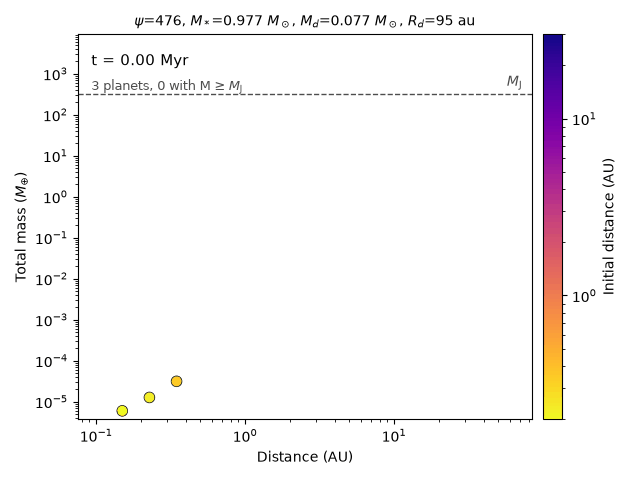

In [8]:
# ==== MOVIE: PLANET MASS vs RADIUS, ONE FRAME PER TIME SNAPSHOT ====
# (Hof, 2026-11-11) Animated version of the tracks plot: each frame shows every
# planet that exists at time t as a circle at (R_p [AU], M_core + M_env [Mearth]),
# with a faded line behind it showing its path up to t.
#   * Colours: insertion radius R_insert_au [AU], same log scale (R_COLOR_LIM_AU),
#     cmap and colour bar as the two static plots above.
#   * Dashed horizontal line: Jupiter mass, M_J = Mjup / Mearth = 317.8 Mearth
#     (DiscEvolution/constants.py), to see which planets become gas giants.
#   * Frames: N_FRAMES_MOVIE times evenly spaced from 0 to t_end [Myr]. Planet rows
#     are written every 5 time steps (thousands of rows), far too many to show one
#     per frame, so each frame uses the last planet row at or before its time
#     (np.searchsorted on "t"). The disc snapshots in time_snap (34 of them in
#     DiscConfig_Hof_add-planets.json) would be too few for smooth motion.
#   * A planet appears only once it is inserted ("SI" planets: NaN rows before
#     t_form), and disappears if the code stops writing it.
# Output (Hof, 2026-11-11, changed for slides): the movie is ALWAYS written as an
# animated GIF with Pillow (no ffmpeg needed; ffmpeg is not installed on this WSL
# machine), then shown in the cell output AS THAT GIF (mime type image/gif), so it
# can be right-clicked / copied straight from the notebook into a slideshow.
#   * The GIF loops forever (matplotlib's PillowWriter writes loop=0), which is what
#     slide software expects for an embedded animation.
#   * The last frame is held for MOVIE_HOLD_END_S [s] before the loop restarts, so
#     the final state can be read during a talk.
#   * Saved to MOVIE_DIR (FIGDIR if set, else ./movies_Hof next to this notebook) as
#     <h5 name>_movie_Mtot_vs_R.gif. If pasting from the notebook gives a still
#     image (some clipboards keep only the first frame), insert that file instead.
#   * The old inline JavaScript player (FuncAnimation.to_jshtml, play/scrub buttons)
#     is still available with SHOW_JS_PLAYER = True; it cannot be copied as a GIF
#     and adds a few MB of PNG frames to the notebook, so it is off by default.
# Uses tracks_pilot from the tracks cell (run it first). Units: t [yr] -> Myr (/1e6).
from matplotlib import animation
from IPython.display import HTML, Image, display
from DiscEvolution.constants import Mjup, Mearth      # both in g

M_JUP_MEARTH = Mjup / Mearth      # Mearth, Jupiter mass (= 317.8)
N_FRAMES_MOVIE = 100              # number of frames (time snapshots)
MOVIE_FPS = 10                    # frames per second in the GIF
MOVIE_DPI = 100                   # dots per inch: default 6.4 x 4.8 in figure -> 640 x 480 px GIF
MOVIE_HOLD_END_S = 2.0            # s, how long the last frame stays on screen before looping
SHOW_TRAILS = True                # draw each planet's path up to the current time
SHOW_JS_PLAYER = False            # True = also show the inline play/scrub player (not copyable as GIF)
# Folder for the GIF (always written now, since the cell output displays that file)
MOVIE_DIR = FIGDIR if FIGDIR else os.path.join(os.getcwd(), "movies_Hof")

# Allow the (optional) inline player to exceed matplotlib's default 20 MB embed limit (in MB)
mpl.rcParams["animation.embed_limit"] = 100


def make_planet_movie_Hof(data, n_frames=N_FRAMES_MOVIE, fps=MOVIE_FPS, dpi=MOVIE_DPI,
                          cmap="plasma_r", r_color_lim=R_COLOR_LIM_AU,
                          show_trails=SHOW_TRAILS, hold_end_s=MOVIE_HOLD_END_S,
                          xlim=None, ylim=None, movie_dir=MOVIE_DIR, fname=None):
    """
    Build a FuncAnimation of planet total mass [Mearth] vs radius [AU] over time.
        data   : dict from load_planet_tracks_Hof()
        xlim, ylim : axis limits; None = from the data (all planets, all times),
                     with ylim widened to always include the Jupiter-mass line
        hold_end_s : s, extra time the last frame is shown before the GIF loops
        movie_dir  : directory the GIF is written to (created if needed)
        fname      : the .h5 path, used to name the GIF
    Returns (anim, gif_path): the FuncAnimation and the path of the saved GIF.
    """
    t_all_Myr = data["t_yr"] / 1e6                                       # yr -> Myr
    P = data["planets"]
    if not P:
        print("No planets to animate.")
        return None, None

    # Per planet: radius [AU] and total mass [Mearth], padded with NaN to the
    # length of "t" so every planet can be indexed with the same row number
    nt = len(t_all_Myr)
    R_arr = np.full((len(P), nt), np.nan)
    M_arr = np.full((len(P), nt), np.nan)
    for k, p in enumerate(P):
        n = len(p["Rp_au"])
        R_arr[k, :n] = p["Rp_au"]
        M_arr[k, :n] = p["Mc_Mearth"] + p["Me_Mearth"]
    good = np.isfinite(R_arr) & np.isfinite(M_arr) & (M_arr > 0)

    # Axis limits from all finite points (0.2 dex padding in log space)
    if xlim is None:
        xlim = (R_arr[good].min() / 10**0.2, R_arr[good].max() * 10**0.2)          # AU
    if ylim is None:
        ylim = (M_arr[good].min() / 10**0.2,
                max(M_arr[good].max(), M_JUP_MEARTH) * 10**0.3)                     # Mearth

    norm = mpl.colors.LogNorm(vmin=r_color_lim[0], vmax=r_color_lim[1])  # AU
    cmap_obj = plt.get_cmap(cmap)
    colors = [cmap_obj(norm(p["R_insert_au"])) for p in P]

    fig, ax = plt.subplots(dpi=dpi)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlim(xlim); ax.set_ylim(ylim)
    ax.set_xlabel("Distance (AU)")
    ax.set_ylabel("Total mass ($M_⊕$)")

    # Jupiter mass reference line (Mearth), labelled at the right edge
    ax.axhline(M_JUP_MEARTH, color="0.3", linestyle="--", linewidth=1, zorder=1)
    ax.text(0.98, M_JUP_MEARTH * 1.15, r"$M_\mathrm{J}$", transform=ax.get_yaxis_transform(),
            ha="right", va="bottom", color="0.3", fontsize=10)

    pr = data["params"]
    ax.set_title(rf"$\psi$={pr['psi']:g}, $M_*$={pr['Ms']:g} $M_\odot$, "
                 rf"$M_d$={pr['M']:.2g} $M_\odot$, $R_d$={pr['Rd']:g} au"
                 + ("" if data["complete"] else "  [run incomplete]"), fontsize=10)
    sm = mpl.cm.ScalarMappable(cmap=cmap_obj, norm=norm)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, pad=0.02)
    cbar.set_label("Initial distance (AU)")

    # Artists updated each frame: one trail line per planet, one scatter for the
    # current positions, and the time stamp
    trails = [ax.plot([], [], color=c, alpha=0.4, linewidth=1)[0] for c in colors] if show_trails else []
    dots = ax.scatter([], [], s=60, edgecolors="k", linewidths=0.5, zorder=5)
    t_text = ax.text(0.03, 0.95, "", transform=ax.transAxes, va="top", fontsize=11)
    n_text = ax.text(0.03, 0.88, "", transform=ax.transAxes, va="top", fontsize=9, color="0.3")
    plt.tight_layout()

    # Frame times [Myr] and, for each, the last planet row with t <= frame time
    frame_t_Myr = np.linspace(0.0, np.nanmax(t_all_Myr), n_frames)
    frame_row = np.clip(np.searchsorted(t_all_Myr, frame_t_Myr, side="right") - 1, 0, nt - 1)

    # Hold the last frame: n_hold extra frames that all redraw the final time, i.e.
    # hold_end_s [s] at fps frames/s. (Pillow merges identical consecutive frames into
    # one longer frame, so this adds almost nothing to the GIF size.)
    n_hold = int(round(hold_end_s * fps))

    def update(i):
        i = min(i, n_frames - 1)                 # frames >= n_frames repeat the last one
        j = frame_row[i]
        alive = good[:, j]                       # planets that exist at this row
        if alive.any():
            dots.set_offsets(np.column_stack([R_arr[alive, j], M_arr[alive, j]]))
            dots.set_facecolors([colors[k] for k in np.flatnonzero(alive)])
        else:
            dots.set_offsets(np.empty((0, 2)))
        for k, ln in enumerate(trails):
            m = good[k, :j + 1]
            ln.set_data(R_arr[k, :j + 1][m], M_arr[k, :j + 1][m])
        n_giant = int(np.sum(M_arr[alive, j] >= M_JUP_MEARTH))
        t_text.set_text(f"t = {t_all_Myr[j]:.2f} Myr")
        n_text.set_text(f"{alive.sum()} planets, {n_giant} with M ≥ $M_\\mathrm{{J}}$")
        return [dots, t_text, n_text, *trails]

    anim = animation.FuncAnimation(fig, update, frames=n_frames + n_hold,
                                   interval=1000 / fps, blit=False)

    # Always write the GIF (looping forever, loop=0 in PillowWriter)
    os.makedirs(movie_dir, exist_ok=True)
    base = os.path.basename(fname) if fname else "planet_movie.h5"
    gif_path = os.path.join(movie_dir, base.replace(".h5", "_movie_Mtot_vs_R.gif"))
    anim.save(gif_path, writer=animation.PillowWriter(fps=fps), dpi=dpi)
    print(f"Saved {gif_path}  ({os.path.getsize(gif_path) / 1e6:.2f} MB)")
    plt.close(fig)               # stop the notebook also showing the last frame as a static figure
    return anim, gif_path


anim_pilot, gif_pilot = make_planet_movie_Hof(tracks_pilot, fname=PILOT_FILE)
if gif_pilot is not None:
    # Show the saved GIF itself (mime type image/gif): right-click the output to
    # copy it into a slideshow. Reading the bytes (not linking the path) keeps the
    # image in the notebook even if the file is moved.
    with open(gif_pilot, "rb") as fh:
        display(Image(data=fh.read(), format="gif"))
    if SHOW_JS_PLAYER:
        display(HTML(anim_pilot.to_jshtml()))

## Planet seeding distribution

Embryo seeds are spaced evenly in log **orbital period**: 20 periods from 1 day to 100 yr (`P_distr`). They are converted to semi-major axes for each star with Kepler's third law, $a = (G M_\star P^2/4\pi^2)^{1/3}$, which in code units ($G$ = AU = M$_\odot$ = 1, `yr` = $2\pi$) is $a\,[\mathrm{AU}] = (M_\star/M_\odot)^{1/3}(P/\mathrm{yr})^{2/3}$.

- **Stars:** the 500 discs of the v5 population (`malanga_mstar_draws_Hof_N500_seed1_xirmin.csv`).
- **`a_distr`:** array of shape (N_star, 20), in AU. `seeds_df` is the same as a long table, with flags for seeds inside the disc grid $[r_{\rm min}, r_{\rm max}]$ and within $5R_0$ (`N_R0_SEED`; about 99% of the initial disc mass).
- **Figure:** one row per disc, ordered by increasing $M_\star$ from the top. Disc ID is on the left and $M_\star$ on the right; $a$ (AU, log scale) is on both the top and bottom axes.
  - **Grey dots:** the 20 seeds. Filled if inside the grid, open if outside (lost).
  - **◀ / ▶:** $r_{\rm min}$ / $r_{\rm max}$.
  - **Green:** $5R_0$.
  - **Faint dashed line:** along each row, to make comparisons within a disc easier.
  - **Coloured segment, from $r_{\rm min}$ to $r_{\rm max}$ only:** the disc's total surface density at $t=0$, $\log_{10}(\Sigma_{\rm tot}/\Sigma_{\rm max})$. Each disc is normalised to its own maximum, so colours compare positions within a disc, not between discs. The colour bar runs from −6 dex (pale) to 0 (dark). It is computed analytically from the code's initial profile $\Sigma \propto (R/R_0)^{-1}e^{-R/R_0}$ (`disc_setup_Hof.py`, γ = 1); the uniform dust-to-gas ratio cancels on normalising.
  - **Size:** the figure is about 100 in tall (`ROW_HEIGHT_SEED_IN` = 0.2 in per row). With `FIGDIR` set it is also saved as a zoomable PDF.

[2.73972603e-03 4.76242131e-03 8.27843970e-03 1.43902774e-02
 2.50143858e-02 4.34821010e-02 7.55842308e-02 1.31386842e-01
 2.28387617e-01 3.97002489e-01 6.90102986e-01 1.19959482e+00
 2.08523622e+00 3.62473230e+00 6.30081335e+00 1.09526016e+01
 1.90387297e+01 3.30947150e+01 5.75280062e+01 1.00000000e+02]
Read 500 stars from /project/6000781/imontesd/DiscEvolution/example/StartHere/notebooks/../config/malanga/malanga_mstar_draws_Hof_N500_seed1_xirmin.csv

Seed radii span 0.00909 - 23.3 AU over all stars (M_star = 0.1 - 1.27 Msun)
Seeds per disc inside the grid [r_min, r_max]: min 12, median 16, max 17 (of 20)
Seeds per disc inside the grid AND within 5 R0: min 9, median 16, max 17 (of 20)
Seeds inside r_min (lost): median 4 per disc | outside r_max: 47 discs have >= 1 | discs with 5 R0 beyond the outermost seed: 317

pilot_v1 star (0.977 Msun): a [AU] = [1.943e-02, 2.809e-02, 4.061e-02, 5.871e-02, 8.487e-02, 1.227e-01,
 1.774e-01, 2.564e-01, 3.708e-01, 5.360e-01, 7.749e-01, 1.120e+00,
 



In [16]:
import numpy as np
import pandas as pd
# (Hof, 2026-11-11) The original line "from constants import G" failed (ModuleNotFoundError): constants.py lives inside
# the DiscEvolution package, so it must be imported as DiscEvolution.constants (as the movie cell does for Mjup).
# G = 1 and yr = 2*pi there (code units: G = AU = Msun = 1, time unit = yr / 2pi).
from DiscEvolution.constants import G, yr

# Embryo orbital periods [yr]: 20 values log-spaced from 1 day (1/365 yr) to 100 yr (user's choice).
P_distr = np.geomspace(1/(365), 100, 20)

print(P_distr)

# According to Kepler's Law, assuming M_star >> M_embryo, P^2 = 4*pi^2/G * a^3 / M_star
# For every star, we calculate the corresponding seeding location distribution (a_distr)
#
# (Hof, 2026-11-11) Completed below. Solving Kepler's law for the semi-major axis:
#     a = (G * M_star * P^2 / (4 pi^2))^(1/3)
# in CODE units: M_star [Msun], a [AU], and P in code time = P[yr] * yr (yr = 2 pi code units per year). With G = 1 this is
#     a[AU] = (M_star/Msun)^(1/3) * (P/yr)^(2/3)
# (check: P = 1 yr around 1 Msun -> a = 1 AU). Each period P_k therefore sits at a different radius around each star, scaling
# as M_star^(1/3): a factor 10 in M_star moves every seed out by 10^(1/3) = 2.15.
#
# "Every star" = the 500 discs of the v5 population (the per-disc draws file read by the popsynth launcher), which also
# gives each disc's grid edges r_min, r_max [AU] and initial characteristic radius R0 [AU]. A seed outside [r_min, r_max]
# would be outside the simulated disc (disc.interp returns the edge value there), so the cell counts them per disc.
# R0: with the gamma = 1 initial profile, M(<R) ~ 1 - exp(-R/R0), so 3 R0 encloses ~95% and 5 R0 ~99% of the initial disc
# mass. (Hof, 2026-11-11, revised) the outer reference is now N_R0_SEED * R0 with N_R0_SEED = 5 (was 3), for the flags,
# printout and figure alike.
N_R0_SEED = 5                      # dimensionless: outer reference radius = N_R0_SEED * R0 [AU] (5 R0 ~ 99% of initial mass)
_frac_R0 = 1 - np.exp(-N_R0_SEED)  # fraction of the initial disc mass inside N_R0_SEED * R0 (gamma = 1)

SEED_DRAWS_FILE = "malanga_mstar_draws_Hof_N500_seed1_xirmin.csv"     # v5 population (xi calibrated on r_min)
_candidates = [os.path.join(os.getcwd(), "..", "config", "malanga", SEED_DRAWS_FILE),           # notebook run from notebooks/
               os.path.join("/home/imontesd/DiscEvolution/example/StartHere/config/malanga", SEED_DRAWS_FILE)]
SEED_DRAWS_PATH = next((p for p in _candidates if os.path.exists(p)), _candidates[-1])
stars_seed = pd.read_csv(SEED_DRAWS_PATH)                                # one row per disc / star
print(f"Read {len(stars_seed)} stars from {SEED_DRAWS_PATH}")

M_star = stars_seed["Mstar_Msun"].to_numpy()                             # Msun, (N_star,)
P_code = P_distr * yr                                                    # yr -> code time units, (N_P,)

# a_distr[i, k] = semi-major axis [AU] of period P_distr[k] around star i; shape (N_star, N_P)
a_distr = (G * M_star[:, None] * P_code[None, :] ** 2 / (4 * np.pi ** 2)) ** (1 / 3)
assert np.isclose((G * 1.0 * (1.0 * yr) ** 2 / (4 * np.pi ** 2)) ** (1 / 3), 1.0)   # 1 yr around 1 Msun = 1 AU

# Long table (one row per star and period) for later use, e.g. to build each disc's planets.Rp list
seeds_df = pd.DataFrame({
    "id": np.repeat(stars_seed["id"].to_numpy(), len(P_distr)),
    "Mstar_Msun": np.repeat(M_star, len(P_distr)),                       # Msun
    "P_yr": np.tile(P_distr, len(M_star)),                               # yr
    "a_au": a_distr.ravel(),                                             # AU
    "rmin_au": np.repeat(stars_seed["rmin_au"].to_numpy(), len(P_distr)),
    "rmax_au": np.repeat(stars_seed["rmax_au"].to_numpy(), len(P_distr)),
    "R0_au": np.repeat(stars_seed["R0_au"].to_numpy(), len(P_distr)),
})
seeds_df["on_grid"] = (seeds_df.a_au >= seeds_df.rmin_au) & (seeds_df.a_au <= seeds_df.rmax_au)
COL_IN_R0_SEED = f"in_{N_R0_SEED}R0"                                     # column name, e.g. "in_5R0"
seeds_df[COL_IN_R0_SEED] = seeds_df.on_grid & (seeds_df.a_au <= N_R0_SEED * seeds_df.R0_au)

# ---- summary ----
print(f"\nSeed radii span {a_distr.min():.3g} - {a_distr.max():.3g} AU over all stars "
      f"(M_star = {M_star.min():.3g} - {M_star.max():.3g} Msun)")
for name, col in [("inside the grid [r_min, r_max]", "on_grid"), (f"inside the grid AND within {N_R0_SEED} R0", COL_IN_R0_SEED)]:
    n = seeds_df.groupby("id")[col].sum()
    print(f"Seeds per disc {name}: min {n.min()}, median {n.median():.0f}, max {n.max()} (of {len(P_distr)})")
_below = (seeds_df.a_au < seeds_df.rmin_au).groupby(seeds_df.id).sum()
_above = (seeds_df.a_au > seeds_df.rmax_au).groupby(seeds_df.id).sum()
print(f"Seeds inside r_min (lost): median {_below.median():.0f} per disc | outside r_max: {int((_above > 0).sum())} discs "
      f"have >= 1 | discs with {N_R0_SEED} R0 beyond the outermost seed: "
      f"{int((N_R0_SEED * stars_seed.R0_au > a_distr[:, -1]).sum())}")

# Example: the pilot_v1 star (M_star = 0.977017 Msun, r_min = 0.09832 AU in config/add-planets/DiscConfig_Hof_add-planets-baseline.json)
_a_pilot = (G * 0.977017 * P_code ** 2 / (4 * np.pi ** 2)) ** (1 / 3)
print("\npilot_v1 star (0.977 Msun): a [AU] =", np.array2string(_a_pilot, precision=3, separator=", "))


# ---- figure: one row per disc (Hof, 2026-11-11, revised; replaces the a vs M_star plot) ----
# x = seed semi-major axis a [AU] (log). y = one row per disc, ordered by INCREASING stellar mass from the top (row 0 =
# lightest star), labelled on the left with the disc ID (CSV column "id") and on the right with M_star [Msun].
# On each row:
#   * grey dots      = the 20 seeds a_distr[i, :]; filled if inside the disc grid [r_min, r_max], open if outside
#                      (an open seed would be outside the simulated disc);
#   * left triangle  "<" = r_min [AU], inner grid edge;   right triangle ">" = r_max [AU], outer grid edge;
#   * green dot      = N_R0_SEED * R0 [AU] (5 R0 ~ 99% of the initial disc mass);
#   * faint dashed line along the row, so the markers of one disc are easy to compare;
#   * (Hof, 2026-11-11) COLOURED segment from r_min to r_max (i.e. only between the blue and red triangles): the disc's
#     TOTAL surface density at t = 0, normalised to ITS OWN maximum (see below), so colours compare positions WITHIN a
#     disc, never magnitudes between discs.
# Total surface density at t = 0. The code starts every disc with (disc_setup_Hof.py, line 555)
#     Sigma_G(R) = Sigma_c (R/R0)^-gamma exp[-(R/R0)^(2-gamma)]      [g/cm^2], gamma = 1 for v5,
# and dust = d2g * Sigma_G with a UNIFORM d2g (0.01; no planetesimals yet), so Sigma_total = (1 + d2g) Sigma_G has the same
# shape. Dividing by the disc's own maximum removes Sigma_c, M0 and d2g:
#     Sigma / Sigma_max = (R/r_min)^-1 exp[-(R - r_min)/R0]           (gamma = 1: Sigma falls monotonically, so max at r_min)
# so no HDF5 output is needed (the v5 runs are on Nibi). Colour = log10(Sigma / Sigma_max), clipped to
# [-SIGMA_DYN_RANGE_DEX, 0]: a LOG scale, because Sigma drops by many orders of magnitude between r_min and r_max
# (R^-1 alone gives 2-3 dex inside R0; at 5 R0 it is typically 1e-5 - 1e-6 of the maximum).
# Rows are ROW_HEIGHT_SEED_IN inches apart, so the figure is very tall (500 x 0.2 in ~ 100 in): scroll through it, or set
# FIGDIR to also save a PDF, which can be zoomed without losing resolution. The x axis is labelled at top and bottom.
ROW_HEIGHT_SEED_IN = 0.2            # inches between neighbouring disc rows (larger = more space per disc)
SEED_LABEL_FS = 6                   # pt, font size of the disc-ID / M_star row labels
SIGMA_DYN_RANGE_DEX = 6.0           # dex: colour scale spans log10(Sigma/Sigma_max) from -6 (palest) to 0 (darkest)
SIGMA_CMAP_SEED = "magma"           # pale yellow (high Sigma) -> near-black (low Sigma); PERCEPTUALLY UNIFORM, so equal steps
                                    # in log Sigma look like equal colour steps ("YlOrBr" packed most change into -1..-2 dex)
N_SIGMA_PTS_SEED = 200              # points per disc (log-spaced in R from r_min to r_max) for the coloured segment
SIGMA_LW_SEED = 3.5                 # pt, width of the coloured segment

_order = np.argsort(M_star, kind="stable")                               # star indices sorted by increasing M_star
_rows = np.arange(len(_order))                                           # row number of each sorted star (0 = top)
_st = stars_seed.iloc[_order].reset_index(drop=True)                     # stars in plotting order
_a = a_distr[_order]                                                     # AU, (N_star, N_P) in plotting order
_ongrid = (_a >= _st.rmin_au.to_numpy()[:, None]) & (_a <= _st.rmax_au.to_numpy()[:, None])
_yy = np.repeat(_rows[:, None], _a.shape[1], axis=1)                     # row of every seed

# Margins are fixed in INCHES (not fractions), so the title / legend / top axis keep the same size whatever the height
_top_in, _bot_in = 2.1, 0.7                                              # inches above / below the axes (top: room for colour bar)
_fig_h = len(_rows) * ROW_HEIGHT_SEED_IN + _top_in + _bot_in             # inches
fig, ax = plt.subplots(figsize=(8.0, _fig_h))
fig.subplots_adjust(top=1 - _top_in / _fig_h, bottom=_bot_in / _fig_h, left=0.09, right=0.88)
# faint dashed guide line along every row (x in axes fraction 0-1, y in data = row number)
ax.hlines(_rows, 0, 1, transform=ax.get_yaxis_transform(), colors="0.5", linestyles="--", linewidth=0.5,
          alpha=0.3, zorder=0)
# (Hof, 2026-11-11) coloured Sigma(t = 0) segment of every disc, r_min -> r_max only, as ONE LineCollection.
# For disc i: N_SIGMA_PTS_SEED radii log-spaced in [r_min, r_max] [AU]; each little segment between neighbouring radii is
# coloured by log10(Sigma/Sigma_max) at its geometric-mean radius.
from matplotlib.collections import LineCollection
_rmin_s, _rmax_s, _R0_s = (_st[c].to_numpy() for c in ("rmin_au", "rmax_au", "R0_au"))          # AU, plotting order
_Rs = np.geomspace(_rmin_s, _rmax_s, N_SIGMA_PTS_SEED, axis=1)           # AU, (N_star, N_SIGMA_PTS_SEED)
_Rmid = np.sqrt(_Rs[:, :-1] * _Rs[:, 1:])                                # AU, segment mid-points (log)
_logS = (np.log10(_rmin_s[:, None] / _Rmid)                              # log10(Sigma/Sigma_max) = -log10(R/r_min)
         - (_Rmid - _rmin_s[:, None]) / _R0_s[:, None] / np.log(10))     #   - (R - r_min)/R0 / ln 10
_yseg = np.repeat(_rows[:, None], N_SIGMA_PTS_SEED - 1, axis=1)          # row of every segment
_segs = np.stack([np.stack([_Rs[:, :-1], _yseg], -1),
                  np.stack([_Rs[:, 1:], _yseg], -1)], axis=2)            # (N_star, n-1, 2 ends, (x, y))
_sig_norm = mpl.colors.Normalize(vmin=-SIGMA_DYN_RANGE_DEX, vmax=0.0)    # dex
_lc = LineCollection(_segs.reshape(-1, 2, 2), cmap=SIGMA_CMAP_SEED, norm=_sig_norm, linewidths=SIGMA_LW_SEED,
                     capstyle="projecting", zorder=1)
# capstyle "projecting": each segment extends half a line width past its ends, so neighbouring segments overlap and no
# white antialiasing seams show between them ("butt" left visible stripes). The extra ~1.75 pt at r_min / r_max is
# hidden under the triangles.
_lc.set_array(np.clip(_logS.ravel(), -SIGMA_DYN_RANGE_DEX, 0.0))         # below -SIGMA_DYN_RANGE_DEX -> palest colour
ax.add_collection(_lc)
# seeds drawn ON the coloured segment: white edge so the dark-grey dots stay visible on the dark end of the colour map
ax.scatter(_a[_ongrid], _yy[_ongrid], s=12, color="0.25", edgecolors="white", linewidths=0.4, zorder=2,
           label="seed, inside the grid")
ax.scatter(_a[~_ongrid], _yy[~_ongrid], s=10, facecolors="none", edgecolors="0.35", linewidths=0.6, zorder=2,
           label="seed, outside the grid (lost)")
# (white edge: keeps the blue triangle visible on the near-black Sigma_max end of the colour map)
ax.scatter(_st.rmin_au, _rows, s=26, marker="<", color="C0", edgecolors="white", linewidths=0.5, zorder=3,
           label=r"$r_{\rm min}$ (inner grid edge)")
ax.scatter(_st.rmax_au, _rows, s=26, marker=">", color="C3", edgecolors="white", linewidths=0.5, zorder=3,
           label=r"$r_{\rm max}$ (outer grid edge)")
ax.scatter(N_R0_SEED * _st.R0_au, _rows, s=14, color="C2", zorder=3,
           label=rf"${N_R0_SEED}R_0$ (~{100 * _frac_R0:.0f}% of initial disc mass)")
ax.set_xscale("log")
ax.set_ylim(len(_rows) - 0.5, -0.5)                                      # inverted: lightest star at the top
ax.margins(y=0)
ax.set_yticks(_rows)
ax.set_yticklabels([str(int(i)) for i in _st["id"]], fontsize=SEED_LABEL_FS)
ax.set_ylabel(r"Disc ID (ordered by increasing $M_\star$, top to bottom)")
ax.set_xlabel("Semi-major axis $a$ (AU)")
# the same log x axis repeated at the TOP of the long plot (secondary axis = identity copy of the bottom one)
ax.secondary_xaxis("top").set_xlabel("Semi-major axis $a$ (AU)")
ax.grid(True, axis="x", which="major", color="0.85", lw=0.6, zorder=0)
# right-hand labels: M_star [Msun] of each row
ax_r = ax.twinx()
ax_r.set_ylim(ax.get_ylim())
ax_r.set_yticks(_rows)
ax_r.set_yticklabels([f"{m:.3f}" for m in _st.Mstar_Msun], fontsize=SEED_LABEL_FS)
ax_r.set_ylabel(r"$M_\star$ ($M_\odot$)")
# title and legend in the top margin, positioned in inches from the top edge (0.15 in and 0.45 in)
fig.suptitle(f"Embryo seeds: {len(P_distr)} periods, {P_distr[0] * 365:.0f} d to {P_distr[-1]:.0f} yr, "
             f"{len(_rows)} discs", fontsize=10, y=1 - 0.15 / _fig_h, va="top")
_h, _l = ax.get_legend_handles_labels()
fig.legend(_h, _l, fontsize=7, loc="upper center", bbox_to_anchor=(0.5, 1 - 0.45 / _fig_h), ncols=3, frameon=False)
# horizontal colour bar for the Sigma segments, in the top margin: 0.95-1.05 in below the top edge, 40% of the width
_cax = fig.add_axes([0.30, 1 - 1.05 / _fig_h, 0.40, 0.10 / _fig_h])
_cb = fig.colorbar(mpl.cm.ScalarMappable(norm=_sig_norm, cmap=SIGMA_CMAP_SEED), cax=_cax, orientation="horizontal",
                   extend="min")                                         # "min" arrow: values below -6 dex are clipped
_cb.set_label(r"$\log_{10}(\Sigma_{\rm tot}/\Sigma_{\rm max})$ at $t=0$, normalised per disc (from $r_{\rm min}$ to $r_{\rm max}$)",
              fontsize=7)
_cb.ax.tick_params(labelsize=6)
if FIGDIR:
    os.makedirs(FIGDIR, exist_ok=True)
    _out = os.path.join(FIGDIR, "seed_distribution_per_disc.pdf")
    fig.savefig(_out)
    print(f"Saved {_out}")
plt.show()